## 📚 05: Collaborative Filtering, Social Intelligence (The "Crowd")— Goal 2

## 🎯 Objective: Find "Taste Neighbors" — The Wisdom of the Crowd

This notebook implements **Goal 2: User-to-User Collaborative Filtering** (Memory-Based). The system identifies users with similar reading patterns and recommends books that those "taste neighbors" loved — but the target user hasn't discovered yet.

> *"If User A and User B both gave 5/4/3 stars to the same 5 books, the system will recommend other high-rated books from User B's library that User A has not yet read."*

---

## 🧠 How It Works

| Step | Action | Description |
|------|--------|-------------|
| **1** | Build User-Item Matrix | Map 28,750 users × 18,335 books (sparse matrix) |
| **2** | Mean-Center Ratings | `rating_centered = rating - user_mean` — normalizes user bias |
| **3** | Calculate Similarity | Cosine similarity focuses on taste patterns, ignores unrated books |
| **4** | Find Neighbors (KNN) | Locate 30 most similar users to the target |
| **5** | Aggregate Liked Books | Collect books neighbors rated above their average |
| **6** | Weighted Scoring | `score = centered_rating × similarity_weight` |
| **7** | Filter + Rank | Exclude already-read books, sort by confidence |
| **8** | Fallback System | 3 levels: Personalized → Genre-based → Popular books |

---

## 📊 Dataset Overview

| Metric | Value |
|--------|-------|
| **Total ratings** | 385,727 |
| **Unique users** | 28,750 |
| **Unique books** | 18,335 |
| **Avg ratings per user** | 13.4 |
| **Avg ratings per book** | 21.0 |
| **Matrix sparsity** | 99.93% (only 0.07% filled) |

---

## ⚙️ Implementation Details

| Component | Choice | Why |
|-----------|--------|-----|
| **Matrix format** | `csr_matrix` (sparse) | Efficient storage (385K entries vs 527M possible) |
| **Similarity metric** | Cosine | Ignores zeros, focuses on relative taste patterns |
| **KNN algorithm** | `brute` | Best for sparse matrices on modern hardware |
| **Neighbors** | 30 | Balance between signal quality and noise |
| **Weighting** | `score = rating_centered × similarity` | Similar users with high ratings contribute more |

---

## 🔄 Fallback Logic (3 Levels)

```text
┌─────────────────────────────────────────────────────────────┐
│ Level 1: Personalized (Collaborative Filtering)            │
│ → Finds similar users → Aggregates their liked books       │
│ → Condition: User has enough ratings AND neighbors exist   │
└─────────────────────────────────────────────────────────────┘
                          │ ❌ No neighbors or no liked books
                          ▼
┌─────────────────────────────────────────────────────────────┐
│ Level 2: Genre-Based (Favorite Genres)                      │
│ → Extracts user's top 3 genres → Recommends popular in-genre│
│ → Condition: User has identifiable genre preferences       │
└─────────────────────────────────────────────────────────────┘
                          │ ❌ No dominant genre detected
                          ▼
┌─────────────────────────────────────────────────────────────┐
│ Level 3: Popularity (Most Rated Books)                      │
│ → Recommends globally popular books                        │
│ → Condition: ALWAYS works (ultimate fallback)              │
└─────────────────────────────────────────────────────────────┘

In [1]:
# ============================================================
# CELL 1 - Load the parquet created in the EDA_Books_ratings.ipynb
# ============================================================

import pandas as pd

similar_people_df = pd.read_parquet("../Data/Books_rating/master_ratings_metadata.parquet")
print(f"Dataset loaded successfully with {similar_people_df.shape[0]:,} rows and {similar_people_df.shape[1]:,} columns!")
similar_people_df.tail(7)

Dataset loaded successfully with 385,727 rows and 7 columns!


,User_id,Title,rating,review_date,review_year,authors_parsed,categories_parsed
385720,AZZVZL4QEHEHO,Our Yanks,4.0,2008-02-01,2008,[Margaret Mayhew],[Fiction]
385721,AZZVZL4QEHEHO,Our Yanks a Love Story,4.0,2008-02-01,2008,[Margaret Mayhew],[Fiction]
385722,AZZVZL4QEHEHO,Redeeming Love,5.0,2011-12-02,2011,[Francine Rivers],[Fiction]
385723,AZZVZL4QEHEHO,A Stranger's Wife,5.0,2003-09-25,2003,[],[]
385724,AZZVZL4QEHEHO,Truly Madly Yours,5.0,2003-11-18,2003,[Rachel Gibson],[Fiction]
385725,AZZVZL4QEHEHO,Twice Loved,5.0,2005-05-20,2005,[LaVyrle Spencer],[Fiction]
385726,AZZVZL4QEHEHO,Years,5.0,2004-01-23,2004,[LaVyrle Spencer],[]


In [2]:
# ============================================================
# CELL 2 - Mean-Centering and Sparse Matrix Creation
# ============================================================

from scipy.sparse import csr_matrix
import numpy as np

# 1. Calculate the mean rating for each user
user_means = similar_people_df.groupby('User_id')['rating'].mean()

# 2. Subtract the mean from each rating (Mean-Centering)
# This identifies which books a user liked "more than their average"
similar_people_df['rating_centered'] = similar_people_df.apply(
    lambda x: x['rating'] - user_means[x['User_id']], axis=1
)

# 3. Create unique mappings for IDs (Matrix indices)
# We need to turn string IDs into row/column numbers
user_ids = similar_people_df['User_id'].unique() 
book_titles = similar_people_df['Title'].unique()

user_to_idx = {id: i for i, id in enumerate(user_ids)}
book_to_idx = {title: i for i, title in enumerate(book_titles)}

# 4. Build the Sparse Matrix
row_ind = similar_people_df['User_id'].map(user_to_idx) # Which user?
col_ind = similar_people_df['Title'].map(book_to_idx) # Which book?
data = similar_people_df['rating_centered'] # What is the rating?

user_item_matrix = csr_matrix((data, (row_ind, col_ind)), 
                               shape=(len(user_ids), len(book_titles)))

print(f"   Sparse Matrix Created!")
print(f"   Shape: {user_item_matrix.shape[0]:,} Users (Rows) x {user_item_matrix.shape[1]:,} Books (Columns)")
print(f"   Non-zero entries: {user_item_matrix.nnz:,}") # Show how many ratings are in the matrix (non-zero entries)

   Sparse Matrix Created!
   Shape: 28,750 Users (Rows) x 18,335 Books (Columns)
   Non-zero entries: 385,727


Example:

#### `user_item_matrix` — Shape: (28,750 rows × 18,335 columns)

| | **The Hobbit** | **1984** | **Pride & Prejudice** | **...** *(18,335 cols)* |
|---|---|---|---|---|
| **User 0** | +0.29 | 0.00 | -0.71 | ... |
| **User 1** | 0.00 | +0.50 | 0.00 | ... |
| **User 2** | -0.50 | 0.00 | +0.30 | ... |
| **User 3** | 0.00 | 0.00 | 0.00 | ... |
| **...** *(28,750 rows)* | ... | ... | ... | ... |

> **`0.00`** → User never rated this book *(most cells are zero!)*  
> **Non-zero** → User rated this book  
> **Density:** only **385,727** non-zero cells out of **527,512,500** possible (~0.07% dense)

In [3]:
similar_people_df.head(10)

,User_id,Title,rating,review_date,review_year,authors_parsed,categories_parsed,rating_centered
0,A01038432MVI9JXYTTK5T,"20, 000 Leagues Under the Sea",5.0,2013-01-14,2013,[Jules Verne],[],0.000
1,A01038432MVI9JXYTTK5T,"The annotated Jules Verne, Twenty thousand lea...",5.0,2013-01-14,2013,[],[],0.000
2,A01038432MVI9JXYTTK5T,A JOURNEY TO THE CENTER OF THE EARTH,5.0,2013-01-14,2013,[Jules Verne],[Fiction],0.000
3,A01038432MVI9JXYTTK5T,The Mysterious Island (Classics Illustrated),5.0,2013-01-14,2013,[Jules Verne],[],0.000
4,A01038432MVI9JXYTTK5T,Twenty Thousand Leagues Under the Sea (Caxton ...,5.0,2013-01-14,2013,"[McClurg, Firm, Booksellers, Chicago]",[],0.000
5,A0134066213WYQXLTVGYT,The Awakening,5.0,2012-12-17,2012,[Kate Chopin],[Fiction],0.125
6,A0134066213WYQXLTVGYT,"The Awakening: Complete, Authoritative Text Wi...",5.0,2012-12-17,2012,[Kate Chopin],[Adultery],0.125
7,A0134066213WYQXLTVGYT,Awakening: Kate Chopin Pb (Case Studies in Con...,5.0,2012-12-17,2012,[New York Public Library Staff],[],0.125
8,A0134066213WYQXLTVGYT,Dracula (G. K. Hall (Large Print)),5.0,2012-12-17,2012,"[Bram Stoker, Grand Theatre Collection (Univer...",[High interest-low vocabulary books],0.125
9,A0134066213WYQXLTVGYT,Public Secrets,5.0,2013-01-04,2013,[],[],0.125


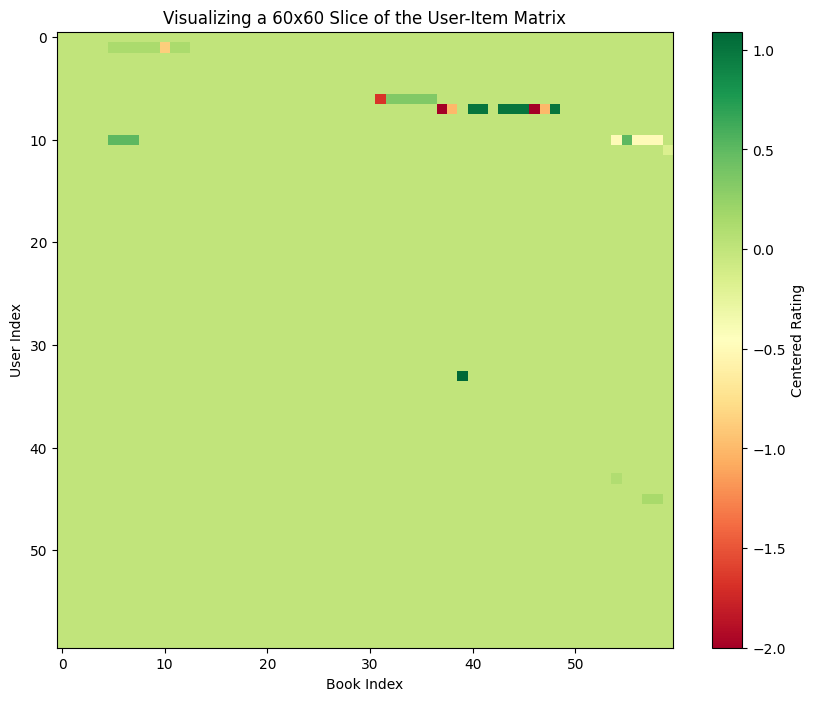

Matrix Sparsity: 99.9268% (The matrix is 99.93% empty!)


In [4]:
# ============================================================
# CELL 3 - Visualizing the "Sparse" Reality
# ============================================================

import matplotlib.pyplot as plt

# We take a small 60x60 slice of the matrix
# and convert it to 'dense' just for visualization
sample_matrix = user_item_matrix[:60, :60].toarray()

plt.figure(figsize=(10, 8))
plt.imshow(sample_matrix, cmap='RdYlGn', interpolation='nearest')
plt.colorbar(label='Centered Rating')
plt.title("Visualizing a 60x60 Slice of the User-Item Matrix")
plt.xlabel("Book Index")
plt.ylabel("User Index")
plt.show()

# Check Sparsity Percentage
total_cells = user_item_matrix.shape[0] * user_item_matrix.shape[1]
sparsity = (1 - (user_item_matrix.nnz / total_cells)) * 100
print(f"Matrix Sparsity: {sparsity:.4f}% (The matrix is {sparsity:.2f}% empty!)")

###  The "Starry Night" Logic: Understanding the Sparse Matrix

The User-Item Matrix maps every user to every book. Because most people haven't read most books, the matrix is mostly empty — like a night sky.

---

### Matrix Elements

| Element | Visual | Value | Meaning |
|---|---|---|---|
| **The Void** | Background (light green) | `0` | Unread book — no information available |
| **The Stars** | Colored pixels scattered across the grid | `≠ 0` | Confirmed rating — the only data the engine uses |

---

### Color Code (Mean-Centering)

Ratings are **mean-centered** (user's average subtracted from their score), so colors represent **relative taste**, not absolute numbers.

| Color | Signal | Meaning |
|---|---|---|
| 🟩 Dark Green `(+)` | Positive | User liked this book **more** than their usual average |
| 🟧 Red / Orange `(-)` | Negative | User liked this book **less** than their usual average |
| 🟨 Yellow / Neutral | Baseline | User felt **average** about this book vs. their other ratings |

---

### How This Drives "Similar People" Recommendations (Goal 2)

| Step | Action | Description |
|---|---|---|
| **1. Find Neighbors** | Overlap detection | Users with matching 🟩 Green and 🟧 Red stars on the same books are identified as mathematical neighbors |
| **2. Generate Suggestions** | Fill the void | Green stars that User B has where User A has a void → those "missing stars" become the recommendations |

In [5]:
# ============================================================
# CELL 4 - Building the K-Nearest Neighbors Engine
# ============================================================
from sklearn.neighbors import NearestNeighbors

# 1. Initialize the Model
# n_neighbors=20: look for the 20 people most similar to our target
# metric='cosine': Best for sparse data to find "taste patterns"
# algorithm='brute': Good for sparse matrices on modern hardware
model_knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=20, n_jobs=-1)

# 2. Fit the model to our Starry Night (User-Item Matrix)
# This doesn't actually "calculate" everything yet; it just builds an index
# so we can query it instantly.
model_knn.fit(user_item_matrix)

print("Similarity Engine is ready!")

Similarity Engine is ready!


KNN with cosine similarity finds users who rate books the SAME WAY
(above/below their average) — even if they've rated completely different books!

In [13]:
# ============================================================
# CELL 5 - FINDING A TARGET USER WITH 10+ RATINGS (For Testing The Function)
# ============================================================

# 1. Count ratings per user
user_activity = similar_people_df['User_id'].value_counts()

# 2. Filter for users with exactly # ratings
active_users = user_activity[user_activity == 10]

print(f"Total users with # ratings: {len(active_users):,}")
print("\nHere are # User_ids you can test:")
print(active_users.head(5))

# 3. Pick a random one from this list to test your function
sample_user = active_users.index[0] # Picking the 1st one in the list
print(f"\nTry testing with this User_id: {sample_user}")

Total users with # ratings: 1,165

Here are # User_ids you can test:
User_id
A10250WFWWKGWV    10
A102P9UKBY9P75    10
A102VPNZTRP1YA    10
A103YPVK70AGXR    10
A10JQQVC4L91RD    10
Name: count, dtype: int64

Try testing with this User_id: A10250WFWWKGWV


In [14]:
# ============================================================
# CELL 6 - Diagnostic: Check if KNN finds any neighbors for this user
# ============================================================

target_user = "A10250WFWWKGWV"

if target_user in user_to_idx:
    idx = user_to_idx[target_user]
    print(f"User index: {idx}")
    
    # Get neighbors
    distances, indices = model_knn.kneighbors(user_item_matrix[idx], n_neighbors=10)
    
    print(f"Indices shape: {indices.shape}")
    print(f"Indices: {indices}")
    print(f"Number of neighbors found: {indices.shape[1]}")
    
    if indices.shape[1] <= 1:
        print("\n❌ PROBLEM: KNN found NO neighbors for this user!")
        print("   This means the user's taste pattern is unique.")
        print("   The function will use popular books as fallback.")
    else:
        print(f"\n✅ Found {indices.shape[1] - 1} neighbors (excluding self)")
else:
    print(f"User {target_user} not found in matrix")

User index: 20
Indices shape: (1, 10)
Indices: [[   20  1357  3432  2860 17571 16601 23813  9276 27552 13462]]
Number of neighbors found: 10

✅ Found 9 neighbors (excluding self)


In [10]:
# ============================================================
# CELL 7 - Recommender Function
# ============================================================

def analyze_and_recommend_v3(target_user_id, n_recs=5, n_neighbors=30):

    if target_user_id not in user_to_idx:
        return print(f"❌ User {target_user_id} not found. User should have at least 5 ratings.")
    
    # --- USER PROFILE ---
    user_data = similar_people_df[similar_people_df['User_id'] == target_user_id].sort_values(by='rating', ascending=False) # Get all ratings for this user, sorted by rating
    
    print(f"\n📖 USER PROFILE: {target_user_id}")
    print(f"Total unique books rated: {len(user_data)}")
    print("-" * 60)
    print(f"{'TITLE':<55} | {'RATING':<6} | {'GENRE'}")
    
    for _, row in user_data.head(10).iterrows():
        genre = row['categories_parsed'][0] if len(row['categories_parsed']) > 0 else "Unknown" # gets the first genre from the list, or "Unknown" if empty
        title = str(row['Title'])[:52] # Truncate title for display
        print(f"{title:<55} | {row['rating']:<6} | {genre}")
    
    print("\n" + "-"*80 + "\n")
    
    # --- FIND NEIGHBORS ---
    user_idx = user_to_idx[target_user_id] # Converts the string User ID (e.g., "A102P9UKBY9P75") to a matrix index number (e.g., 157)
    
    # Creates a set of book titles the user already rated (for filtering)
    already_read = set(user_data['Title'])
    
    try:
        # Who are the 31 most similar users to this one?" (30 + 1 because the first is the user themselves)
        distances, indices = model_knn.kneighbors(user_item_matrix[user_idx], n_neighbors=n_neighbors+1)
        # Takes the neighbor indices and SKIPS the first one (which is the user themselves)
        neighbor_indices = indices.flatten()[1:]
        # Takes the corresponding distances (0 = identical, 1 = completely different)
        neighbor_distances = distances.flatten()[1:]
        
        if len(neighbor_indices) == 0:
            raise ValueError("No neighbors found") # stops the function and jumps to the except block if no neighbors are found
            
        neighbor_ids = user_ids[neighbor_indices] # Convert back to User IDs (e.g., "A102P9UKBY9P75")
        neighbor_similarities = 1 - neighbor_distances # Convert distance to similarity (1 = identical, 0 = completely different)
        
        # Gets ALL ratings from all neighbors in one database query
        neighbor_ratings = similar_people_df[similar_people_df['User_id'].isin(neighbor_ids)]
        
        # Filter for liked books not already read
        liked_books = neighbor_ratings[
            # Filters for books the neighbor liked MORE than their average
            (neighbor_ratings['rating_centered'] > 0) & 
            # Filters out books the user has already read
            (~neighbor_ratings['Title'].isin(already_read))
        ]
        
        if len(liked_books) == 0:
            raise ValueError("No liked books from neighbors") # stops the function and jumps to the except block if no neighbors are found
        
        # Calculate scores
        # Creates a dictionary mapping {User_ID: similarity_score}
        sim_lookup = dict(zip(neighbor_ids, neighbor_similarities))
        liked_books = liked_books.copy()
        # Adds a column with how similar each neighbor is to the user
        liked_books['weight'] = liked_books['User_id'].map(sim_lookup)
        # Multiplies "how much they liked it" × "how similar they are"
        liked_books['weighted_score'] = liked_books['rating_centered'] * liked_books['weight']
        # Groups by book title and adds up scores from all neighbors, then sorts (default 5 recommendations)
        candidate_scores = liked_books.groupby('Title')['weighted_score'].sum().sort_values(ascending=False).head(n_recs)
        
        if len(candidate_scores) == 0:
            raise ValueError("No candidate scores")
            
        # --- DISPLAY PERSONALIZED RECOMMENDATIONS ---
        print(f"PERSONALIZED RECOMMENDATIONS (based on {len(neighbor_ids)} similar readers):")
        print("-" * 60)
        # Loops through recommendations with a counter starting at 1
        for i, (book, score) in enumerate(candidate_scores.items(), 1):
            # Pulls metadata (authors, genres) for the recommended book
            meta = similar_people_df[similar_people_df['Title'] == book].iloc[0]
            # FIXED: Use len() instead of direct truth check
            genre = meta['categories_parsed'][0] if len(meta['categories_parsed']) > 0 else "Unknown"
            # Joins up to 2 authors with commas (e.g., "J.R.R. Tolkien, Christopher Tolkien")
            authors = ', '.join(meta['authors_parsed'][:2]) if len(meta['authors_parsed']) > 0 else "Unknown"
            print(f"{i}. {book}")
            print(f"   Authors: {authors} | Genre: {genre}")
            print(f"   Confidence: {score:.2f}\n")
            
    except (ValueError, IndexError) as e:
        # --- FALLBACK 1: Popular books in user's favorite genres ---
        print(f"⚠️ No personalized recommendations found (reason: {e})")
        
        # Creates empty list to collect all genres from user's books
        user_genres = []
        for _, row in user_data.iterrows():
            # Use len() instead of direct truth check
            if len(row['categories_parsed']) > 0:
                # Adds genres from each book to the list
                user_genres.extend(row['categories_parsed'])
        
        if user_genres:
            from collections import Counter
            top_genres = Counter(user_genres).most_common(3) # Counts genre frequency and returns top 3 (e.g., [('History', 5), ('Fiction', 3)])
            print(f"\n📚 RECOMMENDATIONS BASED ON YOUR FAVORITE GENRES: {[g[0] for g in top_genres]}\n")
            
            # Find popular books in those genres
            genre_recs = []
            for genre, _ in top_genres:
                # Filters dataframe to only books that belong to this genre
                genre_books = similar_people_df[
                    # Checks each book's categories list for the target genre (FIXED: use len() > 0)
                    similar_people_df['categories_parsed'].apply(lambda x: genre in x if len(x) > 0 else False)
                ]
                # Finds the most frequently rated books in that genre
                top_in_genre = genre_books.groupby('Title').size().nlargest(n_recs)
                # Ensures no duplicates and no books user already read
                for book in top_in_genre.index:
                    if book not in already_read and book not in genre_recs:
                        genre_recs.append(book)
                        if len(genre_recs) >= n_recs:
                            break
                if len(genre_recs) >= n_recs:
                    break
            
            for i, book in enumerate(genre_recs[:n_recs], 1):
                meta = similar_people_df[similar_people_df['Title'] == book].iloc[0]
                # FIXED: Use len() instead of direct truth check
                genre = meta['categories_parsed'][0] if len(meta['categories_parsed']) > 0 else "Unknown"
                print(f"{i}. {book}")
                print(f"   Genre: {genre}\n")
            return
        
        # --- FALLBACK 2: Popular books overall ---
        print("\n📚 MOST POPULAR BOOKS IN THE CATALOG:\n")
        # Counts how many times each book appears, takes top N
        popular_books = similar_people_df.groupby('Title').size().nlargest(n_recs)
        # Loops through popular books with a counter starting at 1
        for i, (book, count) in enumerate(popular_books.items(), 1):
            meta = similar_people_df[similar_people_df['Title'] == book].iloc[0]
            # FIXED: Use len() instead of direct truth check
            genre = meta['categories_parsed'][0] if len(meta['categories_parsed']) > 0 else "Unknown"
            print(f"{i}. {book}")
            # Shows popularity metric so user understands why it was recommended
            print(f"   Genre: {genre} | Rated by {count} people\n")

### Hybrid Recommendation Engine — Fallback Logic

```
User A (history lover, 15 ratings)
┌─────────────────────────────────────────────────────────────┐
│ Level 1: Found 30 similar history readers                   │
│ → Personalized recommendations: ✅ "The GI Offensive"       │
└─────────────────────────────────────────────────────────────┘

User B (unique taste, 8 ratings)
┌─────────────────────────────────────────────────────────────┐
│ Level 1: No similar neighbors found                     ❌  │
│ Level 2: Favorite genre = "Experimental Poetry"             │
│ → Genre recommendations: ✅ "Selected Poems of..."          │
└─────────────────────────────────────────────────────────────┘

User C (new user, 5 ratings, all different genres)
┌─────────────────────────────────────────────────────────────┐
│ Level 1: No similar neighbors found                     ❌  │
│ Level 2: No dominant genre detected                     ❌  │
│ Level 3: Popular books: ✅ "The Hobbit", "1984"...          │
└─────────────────────────────────────────────────────────────┘
```

---

| Level | Strategy | Trigger Condition |
|---|---|---|
| **Level 1** | Collaborative Filtering — find taste neighbors | User has enough ratings and similar users exist |
| **Level 2** | Genre-Based Fallback — recommend from favorite genre | No neighbors found but dominant genre is identifiable |
| **Level 3** | Popularity Fallback — recommend top-rated books | No neighbors and no dominant genre detected |

In [15]:
# ============================================================
# CELL 8 - Using the Recommender Function
# ============================================================

# Test it with a user
analyze_and_recommend_v3("A10250WFWWKGWV")


📖 USER PROFILE: A10250WFWWKGWV
Total unique books rated: 10
------------------------------------------------------------
TITLE                                                   | RATING | GENRE
America Alone: The End of the World as We Know It       | 5.0    | Political Science
Liberal Fascism: The Secret History of the American     | 5.0    | History
Women Who Make the World Worse : and How Their Radic    | 5.0    | Social Science
Amateur Marriage                                        | 4.0    | Fiction
THE BRETHREN INSIDE THE SUPREME COURT                   | 4.0    | Political Science
The Female Thing: Dirt, Sex, Envy, Vulnerability        | 4.0    | Social Science
Hot Damn! : Alligators in the Casino, Nude Women in     | 3.0    | Humor
Imperial Life in the Emerald City                       | 3.0    | Unknown
Love My Rifle More than You: Young and Female in the    | 3.0    | Biography & Autobiography
Myths, Lies, and Downright Stupidity: Get Out the Sh    | 3.0    | Unknown

----

### TO KEEP IN MIND:


### Summary: Handling Zero-Variance Users (All 5-Star Raters)

### 1. Why Use `rating_centered` Instead of Raw Ratings?

**Problem:** Different users have different rating scales.

| User Type | Raw Rating for "Good" Book | Raw Rating for "Amazing" Book | Issue |
|-----------|---------------------------|------------------------------|-------|
| Tough rater | 3 stars | 4 stars | Low raw scores |
| Generous rater | 4 stars | 5 stars | High raw scores |

**Without centering:** A generous user's "good" book (4 stars) looks BETTER than a tough user's "amazing" book (4 stars) → WRONG!

**With centering:** Subtract user's average rating.

Now both show the RELATIVE preference. The model compares behavior, not absolute scores.

### 2. Two Approaches for Zero-Variance Users (All 5-Star Raters)

**The scenario:** A user who rates EVERY book as 5 stars → variance = 0 → breaks collaborative filtering models.

### Approach 1: Add Tiny Random Noise

```python
# Before: zero variance (breaks models)
user_ratings = [5, 5, 5, 5, 5]

# After: add tiny noise (±0.001)
import numpy as np
noise = np.random.normal(0, 0.001, size=len(user_ratings))
user_ratings = user_ratings + noise
# Result: [5.0003, 4.9997, 5.0001, 4.9998, 5.0002]
```

### Approach 2: Implicit Feedback (Read/Didn't Read)

```python
# Before: explicit ratings
ratings_data = [(user_A, book_X, 5), (user_A, book_Y, 4)]

# After: binary feedback (1 = engaged/read)
implicit_data = [(user_A, book_X, 1), (user_A, book_Y, 1)]
# All ratings become 1. Missing interactions = 0 (didn't read)
```

### 3. Two Approaches for Zero-Variance Users (All 5-Star Raters)

**Goal 3's hybrid approach** uses embeddings + collaborative filtering, which naturally bypasses the zero-variance issue.
```python
# All-5s user's reading history:
books_read = ["Dune", "Foundation", "Hobbit", "1984", "Brave New World"]
# All rated 5 stars (zero variance)

# What the embedding model sees:
dune_embedding = [0.8, 0.1, 0.05]        # Sci-Fi heavy
foundation_embedding = [0.75, 0.1, 0.08] # Sci-Fi heavy
hobbit_embedding = [0.6, 0.2, 0.1]       # Fantasy/Sci-Fi mix

# Model learns: This user likes books in the Sci-Fi embedding cluster

# New book "Hyperion" has embedding [0.78, 0.09, 0.06]
# → Recommended! (rating values never needed)